# Tabular experiments: all figures and tables

This notebook regenerates every figure and table in the paper that comes from the four tabular datasets (**Bank**, **Credit**, **Coupon**, **Cardio**), plus the synthetic capacity-validation simulation (Figure 10). It only reads the saved results in this folder (no model training), except the synthetic simulation, which is rerun here in a few seconds.

| Paper item | Section | Saved results used |
|---|---|---|
| Table 1 (tabular rows) | 1 | `<dataset>/results/main_100runs/*_agents.json` |
| Figure 3(a), Figure 5(a)-(c) | 2 | `<dataset>/results/step_level_100runs/*_runs100.json` |
| Table 2 (tabular rows) | 3 | `<dataset>/results/main_100runs/*_online_summary.csv` |
| Table 3 | 4 | `<dataset>/results/multi_seeds_10runs/*.json` |
| Figure 4, Figure 8 | 5 | `bank/results/minibatch_*` |
| Figure 7 | 6 | `bank/results/free_agent_50runs/` |
| Figure 10 | 7 | simulated here |
| Table 5 | 8 | `bank/results/step_level_100runs/*_step_actions_packed.npz` |
| Table 6 (tabular rows) | 9 | `<dataset>/results/step_level_100runs/*_step_actions_packed.npz` |
| Table 7 | 10 | `bank/results/feature_split_sweep/` |
| Tables 8 and 9 | 11 | `bank/results/{main_100runs, step_level_100runs, eta_sqrtAT_10runs, plugin_10runs, dmd_10runs}/` |
| Table 12 | 12 | `bank/results/half_split_offline_router_10runs/` |

Each agent's standalone accuracy, its features and the number of online tasks T come from the `*_agents.json` files; these set the non-contextual baseline and the endpoints of the capacity plots. Figures are written to `figures/` and tables to `tables/`. Run all cells from the folder that contains this notebook. Requirements: numpy, pandas, scipy, matplotlib (see `README.md`).

**Agent labels.** In the paper, for the tabular datasets, Agent 1 is the XGBoost classifier (remaining features) and Agent 2 is the logistic regression model (random subset of up to 20% of the features). The code numbers them the other way round: action `0` / `capacity_agent0` / "agent 1" in the logs is the logistic regression agent (paper Agent 2), and action `1` / "agent 2" in the logs is XGBoost (paper Agent 1). Hence paper $\alpha_2$ = `capacity_agent0` and $\alpha_1 = 1 -$ `capacity_agent0`.

In [1]:
import json
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "bank" / "results").is_dir(), "Run this notebook from the folder that contains it."
FIG_DIR, TAB_DIR = ROOT / "figures", ROOT / "tables"
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

# folder -> (file prefix, data/feature-split seed, display name)
DATASETS = {
    "bank":   ("banking", 2,  "Bank"),
    "credit": ("credit",  2,  "Credit"),
    "coupon": ("coupon",  9,  "Coupon"),
    "cardio": ("cardio",  11, "Cardio"),
}
POLICIES = ["Logistic TS", "Logistic greedy", "Tree TS", "Tree greedy"]
CAPS_AGENT0 = [0.2, 0.4, 0.5, 0.6, 0.8]          # capacity_agent0 = paper alpha_2 (logistic regression, action 0)
X_FULL = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]      # paper alpha_1 (XGBoost) on the x-axis

POLICY_COLOR = {
    "Logistic TS": "#1f77b4", "Logistic greedy": "#aec7e8",
    "Tree TS": "#d62728", "Tree greedy": "#ff9896",
    "Offline Logistic Un": "#f6b26b", "Offline Tree Un": "#93d17c",
}
RANDOM_COLOR = "gray"


def res_dir(ds):
    return ROOT / ds / "results"


def load_agents(path):
    # Feature split, number of online tasks T and standalone accuracy of each agent (written by the experiment scripts).
    return json.load(open(path))


def accuracies(agents):
    # {1: logistic-regression accuracy (paper Agent 2), 2: XGBoost accuracy (paper Agent 1)}
    return {1: agents["agent1_logistic_regression"]["accuracy"], 2: agents["agent2_xgboost"]["accuracy"]}


def main_agents(ds):
    pfx, seed, _ = DATASETS[ds]
    return load_agents(res_dir(ds) / "main_100runs" / f"{pfx}_seed_{seed}_agents.json")


def load_actions(path):
    # Step-level actions, stored bit-packed: returns {policy: {capacity_agent0: int array (runs, T)}}, 0 = LR, 1 = XGBoost.
    z = np.load(path)
    T, out = int(z["T"]), {}
    for key in z.files:
        if key == "T" or key.endswith("__nruns"):
            continue
        pol, cap = key.rsplit("__", 1)
        out.setdefault(pol, {})[float(cap)] = np.unpackbits(z[key], axis=1, count=T).astype(np.int8)
    return out


def step_actions_file(ds):
    pfx, seed, _ = DATASETS[ds]
    return res_dir(ds) / "step_level_100runs" / f"{pfx}_seed_{seed}_runs100_step_actions_packed.npz"


ACC = {ds: accuracies(main_agents(ds)) for ds in DATASETS}

## 1. Table 1 (tabular rows): summary of datasets and agent performance

In [2]:
rows = []
for ds, (pfx, seed, name) in DATASETS.items():
    a = main_agents(ds)
    feats = set(a["agent1_logistic_regression"]["features"]) | set(a["agent2_xgboost"]["features"])
    rows.append({"Dataset": name, "# Features": len(feats), "# Timesteps/Tasks": a["n_tasks_T"],
                 "Agent 1 Acc.": round(ACC[ds][2], 2), "Agent 2 Acc.": round(ACC[ds][1], 2)})
table1 = pd.DataFrame(rows)
table1.to_csv(TAB_DIR / "table1_tabular_rows.csv", index=False)
table1

,Dataset,# Features,# Timesteps/Tasks,Agent 1 Acc.,Agent 2 Acc.
0,Bank,15,12357,0.91,0.53
1,Credit,23,9000,0.82,0.67
2,Coupon,24,3624,0.73,0.57
3,Cardio,11,21000,0.73,0.59


## 2. Figure 3(a) (Bank) and Figure 5(a)-(c) (Cardio, Coupon, Credit)

Error rate vs. capacity of Agent 1, averaged over 100 randomized task streams. Endpoints are the marginal error rates of the two agents; the dashed gray line is the non-contextual (random) baseline; the flat dotted lines are the offline unconstrained benchmarks.

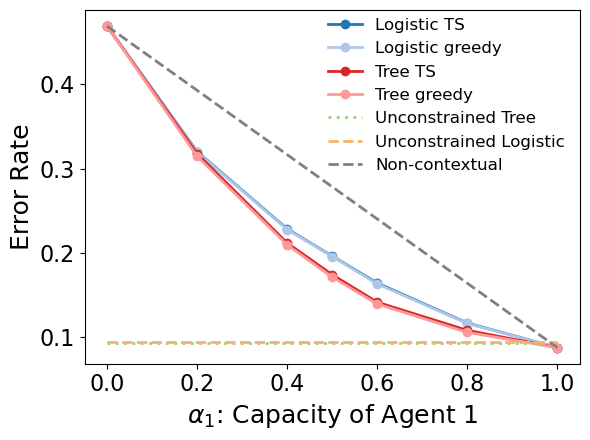

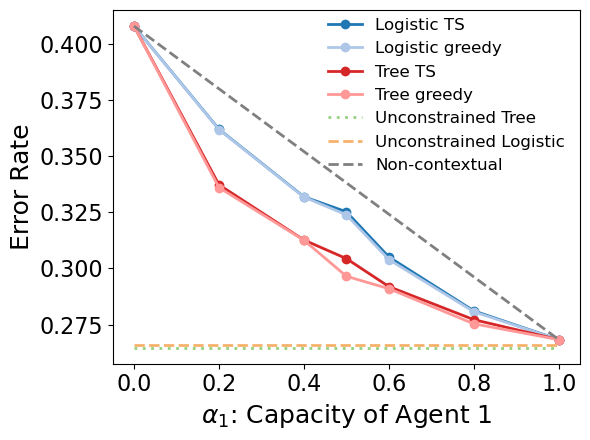

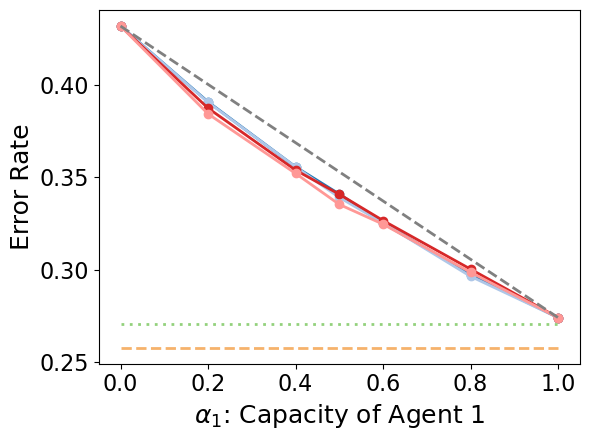

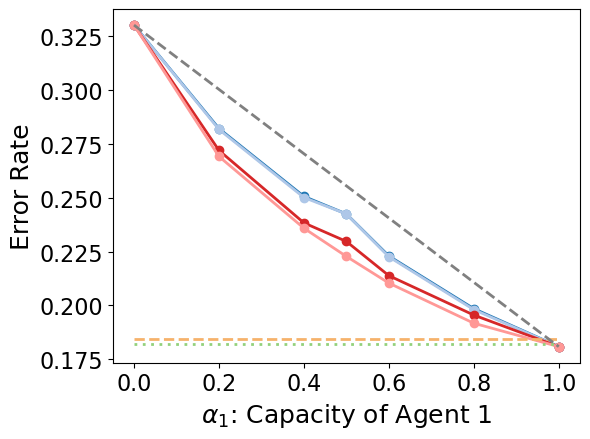

In [3]:
LABEL = {"Offline Tree Un": "Unconstrained Tree", "Offline Logistic Un": "Unconstrained Logistic"}


def plot_capacity_sweep(ds, fname, legend=False):
    pfx, seed, _ = DATASETS[ds]
    data = json.load(open(res_dir(ds) / "step_level_100runs" / f"{pfx}_seed_{seed}_runs100.json"))
    err_lr, err_xgb = 1 - ACC[ds][1], 1 - ACC[ds][2]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for key in POLICIES + ["Offline Tree Un", "Offline Logistic Un"]:
        y = data[key]
        if key.endswith("Un"):
            ax.plot(X_FULL, [y[0]] * len(X_FULL), linewidth=2, color=POLICY_COLOR[key], label=LABEL[key],
                    linestyle=(0, (1, 2)) if key == "Offline Tree Un" else "--")
        else:   # stored in order capacity_agent0 = 0.2..0.8, i.e. alpha_1 = 0.8..0.2
            ax.plot(X_FULL, [err_lr] + y[::-1] + [err_xgb], marker="o", linewidth=2,
                    color=POLICY_COLOR[key], label=key)
    ax.plot([0, 1], [err_lr, err_xgb], linestyle="--", linewidth=2, color=RANDOM_COLOR, label="Non-contextual")
    ax.set_xlim(-0.05, 1.05)
    ax.tick_params(axis="both", labelsize=16)
    ax.set_xlabel(r"$\alpha_1$: Capacity of Agent 1", fontsize=18)
    ax.set_ylabel("Error Rate", fontsize=18)
    if legend:
        ax.legend(fontsize=12, loc="upper right", bbox_to_anchor=(1.0, 1.02), frameon=False)
    plt.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


plot_capacity_sweep("bank",   "fig3a_banking.pdf", legend=True)
plot_capacity_sweep("cardio", "fig5a_cardio.pdf", legend=True)
plot_capacity_sweep("coupon", "fig5b_coupon.pdf")
plot_capacity_sweep("credit", "fig5c_credit.pdf")

## 3. Table 2 (tabular rows): uncertainty across randomized task streams

From the 100-run summaries (`mean_error`, `se_error` = SD / $\sqrt{100}$): each policy's mean error and the non-contextual error are rounded to 3 decimals and the SE to 3 significant digits; error reduction = non-contextual − mean. Each row gives the min–max reduction and the largest SE over 4 policies × 5 capacities, in percentage points.

In [4]:
rows = []
for ds, (pfx, seed, name) in DATASETS.items():
    s = pd.read_csv(res_dir(ds) / "main_100runs" / f"{pfx}_seed_{seed}_runs100_online_summary.csv")
    s = s[s.policy.isin(POLICIES)]
    mean = s.mean_error.map(lambda v: float(f"{v:.3f}"))
    se = s.se_error.map(lambda v: Decimal(f"{v:.2e}"))
    random = (s.capacity_agent0 * (1 - ACC[ds][1]) + (1 - s.capacity_agent0) * (1 - ACC[ds][2])).map(lambda v: float(f"{v:.3f}"))
    red = 100 * (random - mean)
    max_se = (100 * max(se)).quantize(Decimal("0.001"), rounding=ROUND_HALF_UP)
    rows.append({"Dataset": name, "Error reduction vs. non-contextual": f"{red.min():.2f}–{red.max():.2f}",
                 "Max. SE": f"{max_se}"})
table2 = pd.DataFrame(rows)
table2.to_csv(TAB_DIR / "table2_tabular_rows.csv", index=False)
table2

,Dataset,Error reduction vs. non-contextual,Max. SE
0,Bank,4.80–10.70,0.031
1,Credit,1.30–3.40,0.052
2,Coupon,0.60–1.80,0.064
3,Cardio,1.30–4.40,0.070


## 4. Table 3: error rates across seeds (10 runs, $\alpha_1 = \alpha_2 = 0.5$)

In [5]:
rows = []
for ds, (pfx, _, name) in DATASETS.items():
    folder = res_dir(ds) / "multi_seeds_10runs"
    for s in range(5):
        jf = folder / (f"final_avg_error_seed_{s}.json" if ds == "bank" else f"{pfx}_seed_{s}_runs10_avg_error.json")
        d = json.load(open(jf))
        acc = accuracies(load_agents(folder / f"{pfx}_seed_{s}_agents.json"))
        rows.append({"Dataset": name, "Seed": s,
                     "Non-contextual": round(0.5 * (1 - acc[1]) + 0.5 * (1 - acc[2]), 3),
                     "Logistic Greedy": round(d["Logistic greedy"][0], 3),
                     "Tree Greedy": round(d["Tree greedy"][0], 3)})
table3 = pd.DataFrame(rows)
table3.to_csv(TAB_DIR / "table3.csv", index=False)
table3

,Dataset,Seed,Non-contextual,Logistic Greedy,Tree Greedy
0,Bank,0,0.128,0.122,0.113
1,Bank,1,0.136,0.129,0.117
2,Bank,2,0.278,0.195,0.171
3,Bank,3,0.260,0.187,0.180
4,Bank,4,0.124,0.097,0.097
5,Credit,0,0.195,0.190,0.188
6,Credit,1,0.194,0.190,0.188
7,Credit,2,0.256,0.241,0.222
8,Credit,3,0.257,0.242,0.224
9,Credit,4,0.197,0.192,0.188


## 5. Figure 4 (tree greedy) and Figure 8 (logistic greedy): mini-batch assignment on Bank

(a) Online vs. mini-batch with batch size $N_B = 100$, 50 runs. (b) Error vs. batch size at $\alpha_1 = \alpha_2 = 0.5$, 10 runs.

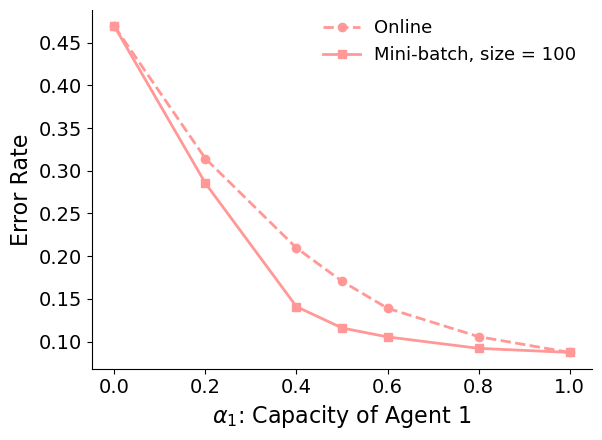

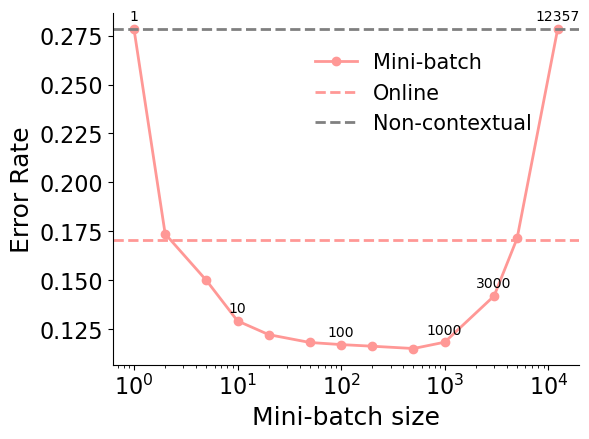

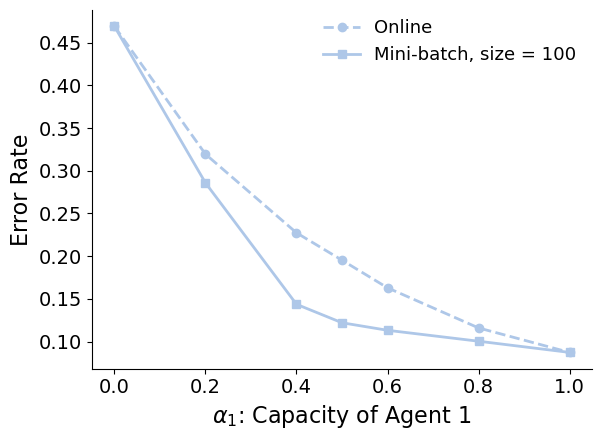

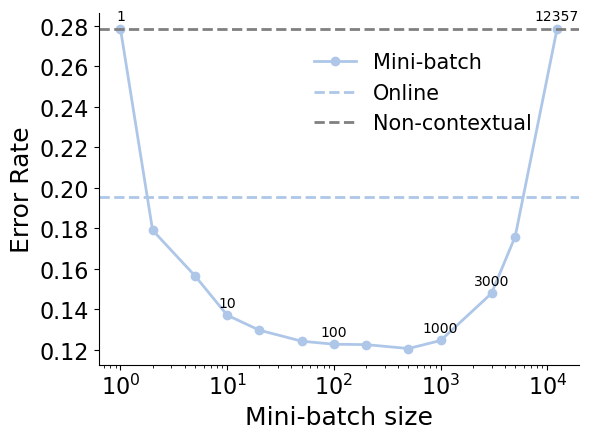

In [6]:
MB = res_dir("bank")
online50 = json.load(open(MB / "minibatch_online_50runs" / "banking_seed_2_runs50.json"))
batch100 = json.load(open(MB / "minibatch_B100_50runs" / "batch_queue_seed_2_final.json"))
BATCH_SIZES = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 3000, 5000, 12357]
batch_err = {b: json.load(open(MB / "minibatch_vary_batch_size_10runs" / f"batch_queue_seed_2_batch_{b}_final.json"))
             for b in BATCH_SIZES}
err_lr, err_xgb = 1 - ACC["bank"][1], 1 - ACC["bank"][2]


def plot_online_vs_batch(policy, fname):
    color = POLICY_COLOR[policy]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot(X_FULL, [err_lr] + online50[policy][::-1] + [err_xgb], marker="o", linestyle="--",
            linewidth=2, color=color, label="Online")
    ax.plot(X_FULL, [err_lr] + batch100[policy][::-1] + [err_xgb], marker="s", linestyle="-",
            linewidth=2, color=color, label="Mini-batch, size = 100")
    ax.set_xlim(-0.05, 1.05)
    ax.tick_params(axis="both", labelsize=14)
    ax.set_xlabel(r"$\alpha_1$: Capacity of Agent 1", fontsize=16)
    ax.set_ylabel("Error Rate", fontsize=16)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=13, loc="upper right", bbox_to_anchor=(1.0, 1.02), frameon=False)
    plt.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


def plot_batch_size(policy, fname, yticks=None):
    color = POLICY_COLOR[policy]
    y = [batch_err[b][policy]["avg_error"] for b in BATCH_SIZES]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot(BATCH_SIZES, y, marker="o", linewidth=2, color=color, label="Mini-batch")
    ax.axhline(online50[policy][CAPS_AGENT0.index(0.5)], linestyle="--", linewidth=2, color=color, label="Online")
    ax.axhline(0.5 * err_lr + 0.5 * err_xgb, linestyle="--", linewidth=2, color=RANDOM_COLOR, label="Non-contextual")
    for b, v in zip(BATCH_SIZES, y):
        if b in [1, 10, 100, 1000, 3000, 12357]:
            ax.annotate(str(b), (b, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=10)
    ax.set_xscale("log")
    if yticks is not None:
        ax.set_yticks(yticks)
    ax.tick_params(axis="both", labelsize=16)
    ax.set_xlabel("Mini-batch size", fontsize=18)
    ax.set_ylabel("Error Rate", fontsize=18)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=15, loc="upper right", bbox_to_anchor=(0.94, 0.94), frameon=False)
    plt.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


plot_online_vs_batch("Tree greedy", "fig4a_banking_tree_greedy_batch_100.pdf")
plot_batch_size("Tree greedy", "fig4b_Tree_greedy_batch_size.pdf",
                yticks=np.arange(0.125, 0.2751, 0.025))   # same y-ticks as the paper
plot_online_vs_batch("Logistic greedy", "fig8a_banking_logistic_greedy_batch_100.pdf")
plot_batch_size("Logistic greedy", "fig8b_Logistic_greedy_batch_size.pdf",
                yticks=np.arange(0.12, 0.2801, 0.02))      # same y-ticks as the paper

## 6. Figure 7: additional unconstrained (free) agent on Bank, 50 runs

Free agent marginal error rate: 0.30


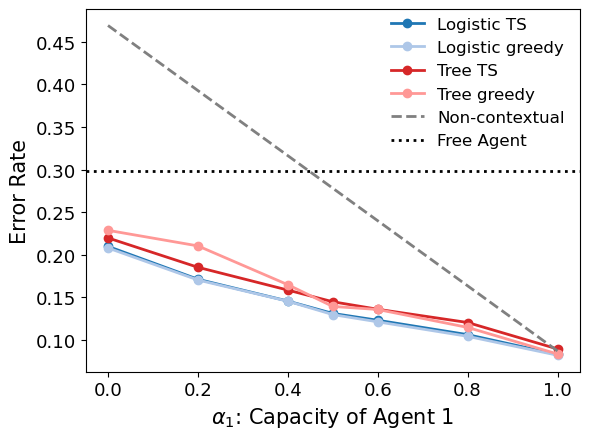

In [7]:
FA = res_dir("bank") / "free_agent_50runs"
free = json.load(open(FA / "banking_seed_2_runs50.json"))
free_err = 1 - load_agents(FA / "banking_seed_2_agents.json")["free_agent"]["accuracy"]
print(f"Free agent marginal error rate: {free_err:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
for pol in POLICIES:
    ax.plot(X_FULL, free[pol][::-1], marker="o", linewidth=2, color=POLICY_COLOR[pol], label=pol)
ax.plot([0, 1], [err_lr, err_xgb], linestyle="--", linewidth=2, color=RANDOM_COLOR, label="Non-contextual")
ax.axhline(free_err, linestyle=":", linewidth=2, color="black", label="Free Agent")
ax.set_xlim(-0.05, 1.05)
ax.tick_params(axis="both", labelsize=13)
ax.set_xlabel(r"$\alpha_1$: Capacity of Agent 1", fontsize=15)
ax.set_ylabel("Error Rate", fontsize=15)
ax.legend(fontsize=12, loc="upper right", bbox_to_anchor=(1.0, 1.02), frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig7_plus_one_free_agent.pdf", bbox_inches="tight")
plt.show()

## 7. Figure 10: synthetic validation of the capacity queue

$x \sim N(0,1)$, $\mu_1(x) = \sigma(2x)$, $\mu_2(x) = \sigma(-2x)$, $(\alpha_1, \alpha_2) = (0.3, 0.7)$, $\eta = 0.5$, 50 task streams of $T = 5{,}000$ (seeds 0–49). Shaded regions are 95% confidence intervals; panel (b) uses a 200-step rolling mean. Also prints the numbers quoted in the text.

x* = 0.524
Analytic lambda_1 - lambda_2 = 0.481
Mean final realized assignment fractions: 0.300, 0.700
Queue-implied eta(Q_t,1 - Q_t,2), averaged over the final 500 tasks: 0.471


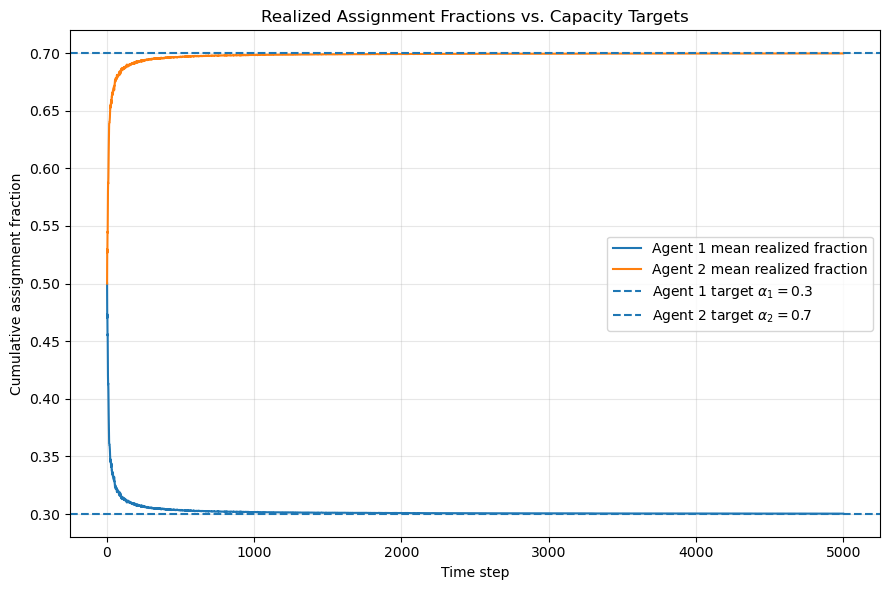

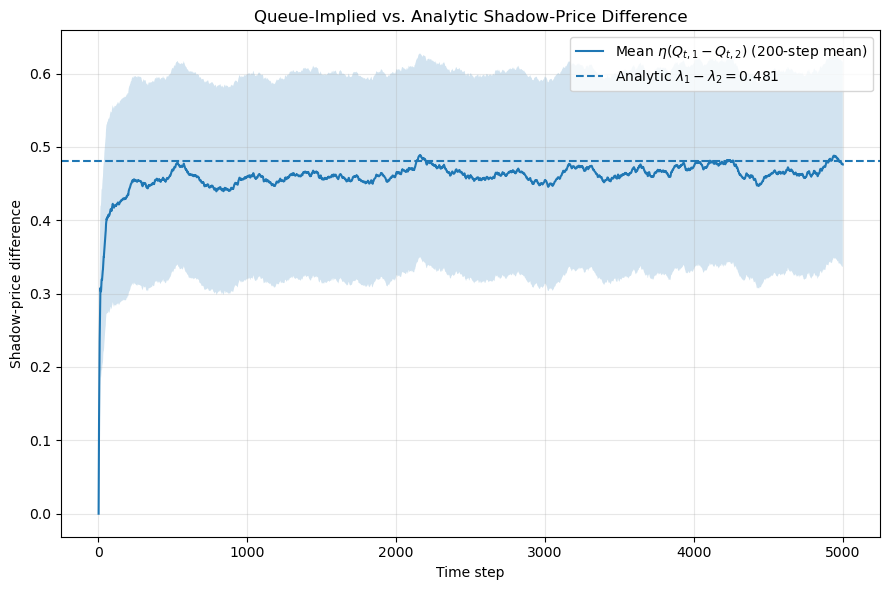

In [8]:
from scipy.special import expit
from scipy.stats import norm, t as student_t

T_SIM, N_SIM_RUNS, BASE_SEED = 5000, 50, 0
ETA_SIM, ALPHA_SIM, BETA_SIM = 0.5, np.array([0.3, 0.7]), 2.0
ROLLING_WINDOW, CI_LEVEL = 200, 0.95

mu_1 = lambda x: expit(BETA_SIM * x)
mu_2 = lambda x: expit(-BETA_SIM * x)
x_star = norm.ppf(1.0 - ALPHA_SIM[0])
analytic_lambda_difference = float(mu_1(x_star) - mu_2(x_star))


def run_one_simulation(seed):
    x_stream = np.random.default_rng(seed).normal(size=T_SIM)
    queue, counts = np.zeros(2), np.zeros(2)
    frac1, price_diff = np.empty(T_SIM), np.empty(T_SIM)
    for i, x_t in enumerate(x_stream):
        price = ETA_SIM * queue
        action = int(np.argmax(np.array([mu_1(x_t), mu_2(x_t)]) - price))
        counts[action] += 1
        frac1[i] = counts[0] / (i + 1)
        price_diff[i] = price[0] - price[1]
        assign = np.zeros(2)
        assign[action] = 1.0
        queue = np.maximum(queue + assign - ALPHA_SIM, 0.0)
    return frac1, price_diff


sims = [run_one_simulation(BASE_SEED + r) for r in range(N_SIM_RUNS)]
frac1 = np.vstack([s[0] for s in sims])
frac2 = 1.0 - frac1
price_diff = np.vstack([s[1] for s in sims])

crit = student_t.ppf(1 - (1 - CI_LEVEL) / 2, df=N_SIM_RUNS - 1)
t_axis = np.arange(1, T_SIM + 1)


def mean_ci(a):
    m, se = a.mean(axis=0), a.std(axis=0, ddof=1) / np.sqrt(a.shape[0])
    return m, m - crit * se, m + crit * se


smooth = lambda v: pd.Series(v).rolling(ROLLING_WINDOW, min_periods=1).mean().to_numpy()

print(f"x* = {x_star:.3f}")
print(f"Analytic lambda_1 - lambda_2 = {analytic_lambda_difference:.3f}")
print(f"Mean final realized assignment fractions: {frac1[:, -1].mean():.3f}, {frac2[:, -1].mean():.3f}")
print(f"Queue-implied eta(Q_t,1 - Q_t,2), averaged over the final 500 tasks: {price_diff[:, -500:].mean():.3f}")

# (a) realized assignment fractions vs. capacity targets
fig, ax = plt.subplots(figsize=(9, 6))
for k, arr in enumerate([frac1, frac2], start=1):
    m, lo, hi = mean_ci(arr)
    ax.plot(t_axis, m, label=f"Agent {k} mean realized fraction")
    ax.fill_between(t_axis, lo, hi, alpha=0.2)
for k, target in enumerate(ALPHA_SIM, start=1):
    ax.axhline(target, linestyle="--", label=rf"Agent {k} target $\alpha_{k}={target}$")
ax.set_xlabel("Time step")
ax.set_ylabel("Cumulative assignment fraction")
ax.set_title("Realized Assignment Fractions vs. Capacity Targets")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig10a_shadow_price_validation_50_runs_assignment_fractions_mean_ci.png", dpi=200, bbox_inches="tight")
plt.show()

# (b) queue-implied vs. analytical shadow-price difference
m, lo, hi = mean_ci(price_diff)
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(t_axis, smooth(m), label=rf"Mean $\eta(Q_{{t,1}}-Q_{{t,2}})$ ({ROLLING_WINDOW}-step mean)")
ax.fill_between(t_axis, smooth(lo), smooth(hi), alpha=0.2)
ax.axhline(analytic_lambda_difference, linestyle="--",
           label=rf"Analytic $\lambda_1-\lambda_2={analytic_lambda_difference:.3f}$")
ax.set_xlabel("Time step")
ax.set_ylabel("Shadow-price difference")
ax.set_title("Queue-Implied vs. Analytic Shadow-Price Difference")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig10b_shadow_price_validation_50_runs_price_difference_mean_ci.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Table 5: capacity enforcement on Bank (and the numbers quoted in the text)

Target capacities $(\alpha_1, \alpha_2) = (0.8, 0.2)$, $\eta = 0.5$, 100 task streams. Convergence = first task at which the cumulative realized assignment fraction is within 0.01 of the target and stays within it for the subsequent 500 tasks. With two agents, Agent 1's deviation from 0.8 equals Agent 2's deviation from 0.2, so it is computed from Agent 2's share (action 0).

In [9]:
CAP, EPS, WINDOW = 0.2, 0.01, 500     # CAP = alpha_2, target share of Agent 2 (logistic regression, action 0)


def running_deviation(actions, capacity=CAP):
    actions = np.asarray(actions)
    frac = np.cumsum(actions == 0, axis=1) / np.arange(1, actions.shape[1] + 1)
    return np.abs(frac - capacity)


def convergence(dev_run):
    # (1-indexed convergence task, any violation after the 500-task window?)
    ok = (dev_run <= EPS).astype(int)
    idx = np.flatnonzero(np.convolve(ok, np.ones(WINDOW, dtype=int), mode="valid") == WINDOW)
    if len(idx) == 0:
        return None, None
    return idx[0] + 1, bool((dev_run[idx[0] + WINDOW:] > EPS).any())


bank_actions = load_actions(step_actions_file("bank"))
rows, n_conv, n_viol, max_final_dev = [], [], [], 0.0
for pol, label in [("Logistic TS", "Logistic TS"), ("Tree TS", "Tree TS"),
                   ("Logistic greedy", "Logistic Greedy"), ("Tree greedy", "Tree Greedy")]:
    dev = running_deviation(bank_actions[pol][CAP])
    T = dev.shape[1]
    res = [convergence(d) for d in dev]
    conv = np.array([c for c, _ in res if c is not None])
    n_conv.append(len(conv))
    n_viol.append(sum(v for _, v in res if v is not None))
    max_final_dev = max(max_final_dev, dev[:, -1].max())
    rows.append({"Policy": label, "Median conv.": round(np.median(conv)), "Mean conv.": round(conv.mean()),
                 "Mean conv. (% T)": f"{100 * conv.mean() / T:.2f}%"})
del bank_actions
table5 = pd.DataFrame(rows)
table5.to_csv(TAB_DIR / "table5.csv", index=False)
display(table5)
print(f"Runs satisfying the convergence criterion (per policy): {n_conv}")
print(f"Runs that later violate the 0.01 tolerance (per policy): {n_viol}")
print(f"Maximum final absolute deviation from the target across all runs: {max_final_dev:.6f}")

,Policy,Median conv.,Mean conv.,Mean conv. (% T)
0,Logistic TS,158,156,1.26%
1,Tree TS,153,156,1.26%
2,Logistic Greedy,132,128,1.04%
3,Tree Greedy,96,103,0.84%


Runs satisfying the convergence criterion (per policy): [100, 100, 100, 100]
Runs that later violate the 0.01 tolerance (per policy): [0, 0, 0, 0]
Maximum final absolute deviation from the target across all runs: 0.000129


## 9. Table 6 (tabular rows): capacity enforcement across datasets

Target: capacity of Agent 2 (logistic regression), $\alpha_2 = 0.2$ (i.e., $\alpha_1 = 0.8$). Per run: mean |realized Agent 2 fraction − 0.2| over the final 5% of the horizon. Reported: worst case over the four policies of the mean and the maximum across 100 runs.

In [10]:
rows = []
for ds in ["bank", "cardio", "credit", "coupon"]:
    acts = load_actions(step_actions_file(ds))
    worst_mean, worst_max = 0.0, 0.0
    for pol in POLICIES:
        dev = running_deviation(acts[pol][CAP])
        k = max(1, int(0.05 * dev.shape[1]))
        final_dev = dev[:, -k:].mean(axis=1)
        worst_mean, worst_max = max(worst_mean, final_dev.mean()), max(worst_max, final_dev.max())
    rows.append({"Dataset": DATASETS[ds][2], "Mean final deviation": round(worst_mean, 4),
                 "Max final deviation": round(worst_max, 4)})
    del acts
table6 = pd.DataFrame(rows)
table6.to_csv(TAB_DIR / "table6_tabular_rows.csv", index=False)
table6

,Dataset,Mean final deviation,Max final deviation
0,Bank,0.0001,0.0001
1,Cardio,0.0001,0.0001
2,Credit,0.0002,0.0002
3,Coupon,0.0004,0.0005


## 10. Table 7: robustness to the feature-split choice (Bank)

Gain over the capacity-matched random baseline as a function of the fraction of features given to Agent 2 (logistic regression; Agent 1 gets the rest). Each row: 5 feature-assignment seeds × 4 contextual policies (20 evaluations) at $\alpha_1 = \alpha_2 = 0.5$, $\eta = 0.5$, 10 task streams per configuration. In the result files, `requested_fraction_agent1` is the fraction given to the logistic regression agent (code numbering).

In [11]:
FS = res_dir("bank") / "feature_split_sweep"
fs = pd.concat([pd.read_csv(f) for f in sorted(FS.glob("*_summary.csv"))], ignore_index=True)
table7 = (fs.groupby("requested_fraction_agent1")["mean_gain_over_random"].agg(["mean", "min", "max"]).round(4)
            .rename_axis("Fraction of features to Agent 2")
            .rename(columns={"mean": "Mean gain", "min": "Min gain", "max": "Max gain"}))
table7.to_csv(TAB_DIR / "table7.csv")
display(table7)

fs["disagreement_mass"] = fs.p1 + fs.p2
r = fs.groupby("policy")[["mean_gain_over_random", "disagreement_mass"]].apply(
    lambda g: g.mean_gain_over_random.corr(g.disagreement_mass))
print(f"Gain positive in {(fs.mean_gain_over_random > 0).sum()} of {len(fs)} evaluations")
print(f"Correlation of gain with disagreement mass p1 + p2 across policies: r = {r.min():.2f}–{r.max():.2f}")

,Mean gain,Min gain,Max gain
Fraction of features to Agent 2,,,
0.1,0.0301,0.0045,0.0470
0.2,0.0429,0.0050,0.1072
0.5,0.0329,0.0051,0.0871
0.8,0.0096,0.0023,0.0172
0.9,0.0086,0.0027,0.0142


Gain positive in 100 of 100 evaluations
Correlation of gain with disagreement mass p1 + p2 across policies: r = 0.80–0.87


## 11. Tables 8 and 9: Bank, comparison with additional online baselines

10 paired task streams (the first 10 of the 100 main streams). Error rate and SE in %. Max window deviation = maximum over runs and over sliding windows of 200 consecutive tasks (excluding windows that end within the first 1,000 tasks) of |share of Agent 1 in the window − α₁|. Table 8 = logistic greedy reward model, Table 9 = tree-based greedy. `*` marks the lowest value per column (bold in the paper).

In [12]:
CAPS_R = [0.2, 0.4, 0.5, 0.6, 0.8]           # capacity_agent0 (LR share); alpha_1 = 1 - c
BR = res_dir("bank")
ROUTE = {  # label: (step-action file, run-level csv, policy-name pattern)
    "Ours, η=√(A/T)":  ("eta_sqrtAT_10runs/banking_seed_2_runs10_step_actions_packed.npz",
                        "eta_sqrtAT_10runs/banking_seed_2_runs10_online_raw_runs.csv", "{m} greedy"),
    "Online plug-in":  ("plugin_10runs/banking_seed_2_runs10_plugin_step_actions_packed.npz",
                        "plugin_10runs/banking_seed_2_runs10_plugin_raw_runs.csv", "Online plug-in {m}"),
    "DMD, Euclidean":  ("dmd_10runs/banking_seed_2_runs10_dmd_step_actions_packed.npz",
                        "dmd_10runs/banking_seed_2_runs10_dmd_raw_runs.csv", "DMD Euclidean {m}"),
    "DMD, entropic":   ("dmd_10runs/banking_seed_2_runs10_dmd_step_actions_packed.npz",
                        "dmd_10runs/banking_seed_2_runs10_dmd_raw_runs.csv", "DMD Entropic {m}"),
}

WINDOW, BURN_IN = 200, 1000                   # sliding-window length; windows ending within the first BURN_IN tasks are skipped


def window_deviation(a, c, window=WINDOW, burn_in=BURN_IN):
    # Per run: max over sliding windows of `window` consecutive tasks of |share of Agent 2 (action 0) in the window - c|,
    # over windows ending after task `burn_in`. With two agents this equals Agent 1's deviation from alpha_1 = 1 - c.
    cs = np.concatenate([np.zeros((a.shape[0], 1)), np.cumsum(a == 0, axis=1)], axis=1)
    share = (cs[:, window:] - cs[:, :-window]) / window       # column j = window ending at task window + j
    end = np.arange(window, a.shape[1] + 1)
    return np.abs(share[:, end > burn_in] - c).max(axis=1)


def collect(route, root, n_runs=10):
    cache, rows = {}, []
    for lab, (fa, fr, pat) in route.items():
        acts = cache.setdefault(fa, load_actions(root / fa))
        raw = pd.read_csv(root / fr)
        for m in ["Logistic", "Tree"]:
            pol = pat.format(m=m)
            for c in CAPS_R:
                a = acts[pol][c][:n_runs]
                e = raw[(raw.policy == pol) & (raw.capacity_agent0.round(2) == c) & (raw.run <= n_runs)].error_rate
                assert len(e) == n_runs
                rows.append({"method": lab, "model": m, "alpha": c, "err": 100 * e.mean(),
                             "se": 100 * e.std(ddof=1) / np.sqrt(n_runs), "max_dev": window_deviation(a, c).max()})
    return pd.DataFrame(rows)


def paper_table(df, methods, model, deviation=True, bold=True):
    x = df[(df.model == model) & df.method.isin(methods)]
    order = CAPS_R[::-1]
    cols = [f"α₁={1 - c:.1f}" for c in order]
    num = x.pivot(index="method", columns="alpha", values="err").loc[methods][order]
    txt = (x.assign(cell=x.err.map("{:.2f}".format) + " (" + x.se.map("{:.2f}".format) + ")")
             .pivot(index="method", columns="alpha", values="cell").loc[methods][order])
    num.columns = txt.columns = cols
    if bold:
        txt = txt.where(num.ne(num.min()), txt + "*")
    out = {"Error rate, % (SE)": txt}
    if deviation:
        dv = x.pivot(index="method", columns="alpha", values="max_dev").loc[methods][order]
        dv.columns = cols
        dtxt = dv.map("{:.3f}".format)
        if bold:
            dtxt = dtxt.where(dv.ne(dv.min()), dtxt + "*")
        out[f"Max deviation over {WINDOW}-task windows"] = dtxt
    return pd.concat(out)


baselines = collect(ROUTE, BR)
METHODS = list(ROUTE)
for num, m in [(8, "Logistic"), (9, "Tree")]:
    t = paper_table(baselines, METHODS, m)
    t.to_csv(TAB_DIR / f"table{num}_bank_{m.lower()}_greedy_baselines.csv")
    print(f"Table {num}: Bank, {m.lower()} greedy reward model   [* = lowest error / deviation per column]")
    display(t)

Table 8: Bank, logistic greedy reward model   [* = lowest error / deviation per column]


α₁=0.2  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)   28.27 (0.05)   
                                    Online plug-in  27.60 (0.14)*   
                                    DMD, Euclidean   28.83 (0.05)   
                                    DMD, entropic    29.55 (0.06)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.055*   
                                    Online plug-in          0.150   
                                    DMD, Euclidean          0.200   
                                    DMD, entropic           0.200   

                                                           α₁=0.4  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)   14.70 (0.08)   
                                    Online plug-in   16.22 (0.18)   
                                    DMD, Euclidean   14.72 (0.08)   
                                    DMD, entropic   14.62 (0.09)*   
Max deviation over 200-task windows Ours, η=√(A/T)         0.055*   
                                    Online plug-in          0.210   
                                    DMD, Euclidean          0.290   
                                    DMD, entropic           0.400   

                                                           α₁=0.5  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)  12.57 (0.07)*   
                                    Online plug-in   13.41 (0.11)   
                                    DMD, Euclidean   12.65 (0.07)   
                                    DMD, entropic    12.58 (0.11)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.045*   
                                    Online plug-in          0.255   
                                    DMD, Euclidean          0.210   
                                    DMD, entropic           0.365   

                                                           α₁=0.6  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)  11.60 (0.09)*   
                                    Online plug-in   12.01 (0.08)   
                                    DMD, Euclidean   11.75 (0.07)   
                                    DMD, entropic    11.90 (0.14)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.055*   
                                    Online plug-in          0.270   
                                    DMD, Euclidean          0.200   
                                    DMD, entropic           0.545   

                                                           α₁=0.8  
                                    method                         
Error rate, % (SE)                  Ours, η=√(A/T)  10.00 (0.07)*  
                                    Online plug-in   10.45 (0.11)  
                                    DMD, Euclidean   10.03 (0.07)  
                                    DMD, entropic    10.22 (0.07)  
Max deviation over 200-task windows Ours, η=√(A/T)         0.045*  
                                    Online plug-in          0.210  
                                    DMD, Euclidean          0.140  
                                    DMD, entropic           0.220

Table 9: Bank, tree greedy reward model   [* = lowest error / deviation per column]


α₁=0.2  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)   28.35 (0.04)   
                                    Online plug-in  25.35 (0.51)*   
                                    DMD, Euclidean   28.86 (0.03)   
                                    DMD, entropic    29.47 (0.04)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.045*   
                                    Online plug-in          0.175   
                                    DMD, Euclidean          0.200   
                                    DMD, entropic           0.200   

                                                           α₁=0.4  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)  14.23 (0.07)*   
                                    Online plug-in   15.08 (0.19)   
                                    DMD, Euclidean   14.45 (0.05)   
                                    DMD, entropic    14.81 (0.05)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.065*   
                                    Online plug-in          0.185   
                                    DMD, Euclidean          0.260   
                                    DMD, entropic           0.400   

                                                           α₁=0.5  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)  11.75 (0.08)*   
                                    Online plug-in   12.25 (0.12)   
                                    DMD, Euclidean   11.93 (0.09)   
                                    DMD, entropic    11.88 (0.08)   
Max deviation over 200-task windows Ours, η=√(A/T)         0.065*   
                                    Online plug-in          0.230   
                                    DMD, Euclidean          0.180   
                                    DMD, entropic           0.350   

                                                           α₁=0.6  \
                                    method                          
Error rate, % (SE)                  Ours, η=√(A/T)   10.79 (0.08)   
                                    Online plug-in   11.20 (0.09)   
                                    DMD, Euclidean   10.78 (0.08)   
                                    DMD, entropic   10.77 (0.09)*   
Max deviation over 200-task windows Ours, η=√(A/T)         0.075*   
                                    Online plug-in          0.290   
                                    DMD, Euclidean          0.160   
                                    DMD, entropic           0.220   

                                                          α₁=0.8  
                                    method                        
Error rate, % (SE)                  Ours, η=√(A/T)   9.21 (0.04)  
                                    Online plug-in   9.40 (0.09)  
                                    DMD, Euclidean   9.23 (0.04)  
                                    DMD, entropic   9.19 (0.05)*  
Max deviation over 200-task windows Ours, η=√(A/T)        0.070*  
                                    Online plug-in         0.360  
                                    DMD, Euclidean         0.165  
                                    DMD, entropic          0.270

## 12. Table 12: Bank, our online policy vs. the offline router (half split)

The 30% held-out set is split in half. The offline router (logistic / random-forest models of each agent's correctness) is fit on the first half using both agents' labels and then frozen; both methods run on the second half (6,179 tasks) with the same 10 task orders and the same virtual queue ($\eta = 0.5$). Error rate in % (SE).

In [13]:
HS = BR / "half_split_offline_router_10runs"
hs_route = {
    "Ours (online)":  ("banking_seed_2_runs10_half_split_step_actions_packed.npz",
                       "banking_seed_2_runs10_half_split_raw_runs.csv", "{m} greedy"),
    "Offline router": ("banking_seed_2_runs10_half_split_step_actions_packed.npz",
                       "banking_seed_2_runs10_half_split_raw_runs.csv", "Offline {m}"),
}
hs = collect(hs_route, HS)
print(f"Online half: T = {int(np.load(HS / hs_route['Ours (online)'][0])['T'])} tasks")
table12 = pd.concat({f"{m} greedy": paper_table(hs, list(hs_route), m, deviation=False, bold=False)
                     .droplevel(0) for m in ["Logistic", "Tree"]})
table12.to_csv(TAB_DIR / "table12_bank_offline_router.csv")
table12

Online half: T = 6179 tasks


α₁=0.2        α₁=0.4        α₁=0.5  \
                method                                                     
Logistic greedy Ours (online)   32.13 (0.09)  22.80 (0.17)  19.62 (0.07)   
                Offline router  31.81 (0.05)  21.85 (0.13)  18.14 (0.11)   
Tree greedy     Ours (online)   31.40 (0.07)  21.02 (0.08)  17.28 (0.07)   
                Offline router  31.30 (0.10)  20.37 (0.08)  17.23 (0.09)   

                                      α₁=0.6        α₁=0.8  
                method                                      
Logistic greedy Ours (online)   16.45 (0.07)  11.89 (0.09)  
                Offline router  14.77 (0.03)  10.35 (0.02)  
Tree greedy     Ours (online)   14.56 (0.07)  11.09 (0.08)  
                Offline router  13.47 (0.06)   9.93 (0.04)